Prompt: I have some data in a file named card_transdata.csv and I want to do an explorator data analysis on it with pandas. Can you load in the data and show me the top five entries along with its shape data types and descriptive statistics. 
<br>Ai: GPT-6 Luna

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the transaction data from the workspace directory.
df = pd.read_csv("card_transdata.csv")

print("Top five entries:")
display(df.head())

print("Shape:", df.shape)
print("\nDataFrame information:")
df.info()

print("Descriptive statistics:")
display(df.describe())

Top five entries:


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
1,10.829943,0.175592,1.294219,1.0,NaN,0.0,0.0,0
2,5.091079,NaN,0.427715,1.0,0.0,0.0,1.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0


Shape: (999, 8)

DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   distance_from_home              999 non-null    float64
 1   distance_from_last_transaction  996 non-null    float64
 2   ratio_to_median_purchase_price  997 non-null    float64
 3   repeat_retailer                 992 non-null    float64
 4   used_chip                       995 non-null    float64
 5   used_pin_number                 997 non-null    float64
 6   online_order                    995 non-null    float64
 7   fraud                           999 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB
Descriptive statistics:


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
count,999.000000,996.000000,997.000000,992.000000,995.000000,997.000000,995.000000,999.000000
mean,26.876607,5.437319,1.655069,0.892137,0.313568,0.117352,0.673367,0.079079
std,63.899697,35.668094,2.351386,0.310364,0.464176,0.322001,0.469218,0.269997
min,0.104184,0.001448,0.016933,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.990543,0.306441,0.468123,1.000000,0.000000,0.000000,0.000000,0.000000
50%,10.340321,0.958539,0.955504,1.000000,0.000000,0.000000,1.000000,0.000000
75%,25.393952,3.137259,1.922025,1.000000,1.000000,0.000000,1.000000,0.000000
max,965.910612,990.070315,36.074366,1.000000,1.000000,1.000000,1.000000,1.000000


Prompt: Display how many values are missing in each column.
<br>Ai: GPT-6 Luna

In [8]:
missing_values_per_column = df.isna().sum(axis=0)
display(missing_values_per_column)

distance_from_home                0
distance_from_last_transaction    3
ratio_to_median_purchase_price    2
repeat_retailer                   7
used_chip                         4
used_pin_number                   2
online_order                      4
fraud                             0
dtype: int64

Prompt: Drop rows with null values and print the first few rows. Rename the df to cleaned_df.
<br>Ai: GPT-6 Luna

In [9]:
cleaned_df = df.dropna().copy()

print("First rows after dropping rows with null values:")
display(cleaned_df.head())

First rows after dropping rows with null values:


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0
5,5.586408,13.261073,0.064768,1.0,0.0,0.0,0.0,0
6,3.724019,0.956838,0.278465,1.0,0.0,0.0,1.0,0


Prompt: Create a visualization depicting which entries are fraud and which are not using seaborn.
<br>Ai: GPT-6 Luna

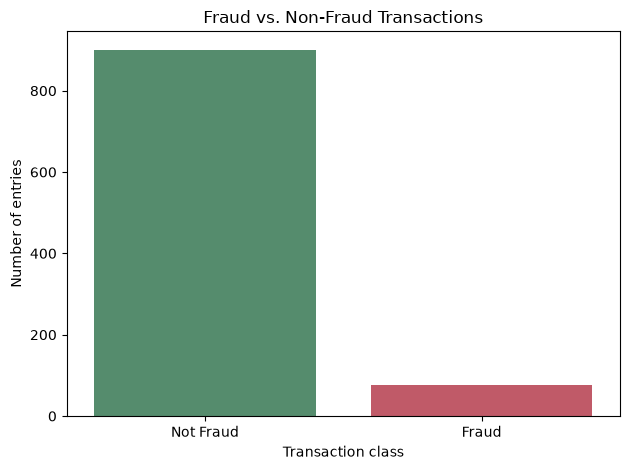

In [11]:

fraud_status = cleaned_df["fraud"].map({0: "Not Fraud", 1: "Fraud"})

sns.countplot(
    x=fraud_status,
    hue=fraud_status,
    order=["Not Fraud", "Fraud"],
    hue_order=["Not Fraud", "Fraud"],
    palette={"Not Fraud": "#4C956C", "Fraud": "#D1495B"},
    legend=False,
)
plt.title("Fraud vs. Non-Fraud Transactions")
plt.xlabel("Transaction class")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

Prompt: Create another visualization showing Used Pin Distribution.
<br>Ai: GPT-6 Luna

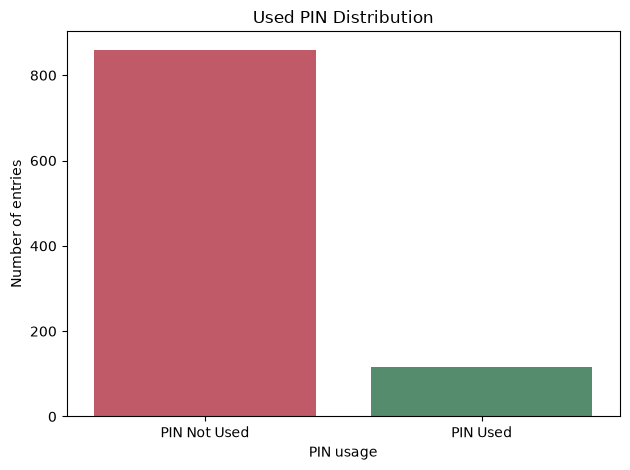

In [12]:

pin_status = cleaned_df["used_pin_number"].map({0: "PIN Not Used", 1: "PIN Used"})

sns.countplot(
    x=pin_status,
    hue=pin_status,
    order=["PIN Not Used", "PIN Used"],
    hue_order=["PIN Not Used", "PIN Used"],
    palette={"PIN Not Used": "#D1495B", "PIN Used": "#4C956C"},
    legend=False,
)
plt.title("Used PIN Distribution")
plt.xlabel("PIN usage")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

Prompt: Create another visualization for Repeat Retailer Distribution.
<br> Ai: GPT-6 Luna

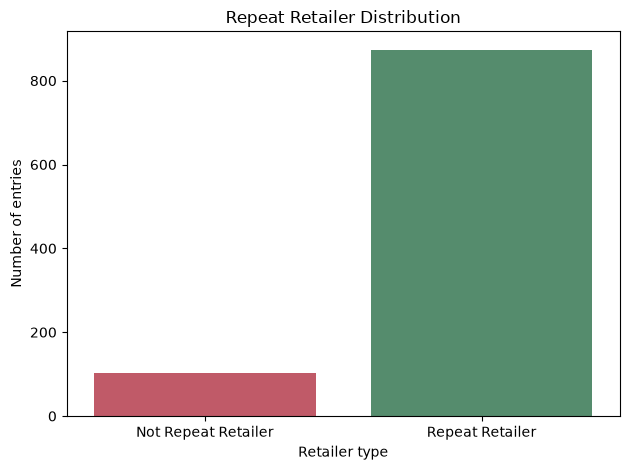

In [13]:

retailer_status = cleaned_df["repeat_retailer"].map(
    {0: "Not Repeat Retailer", 1: "Repeat Retailer"}
)

sns.countplot(
    x=retailer_status,
    hue=retailer_status,
    order=["Not Repeat Retailer", "Repeat Retailer"],
    hue_order=["Not Repeat Retailer", "Repeat Retailer"],
    palette={"Not Repeat Retailer": "#D1495B", "Repeat Retailer": "#4C956C"},
    legend=False,
)
plt.title("Repeat Retailer Distribution")
plt.xlabel("Retailer type")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

Prompt: Create another visualization of Online order distribution.
<br>Ai: GPT-6 Luna

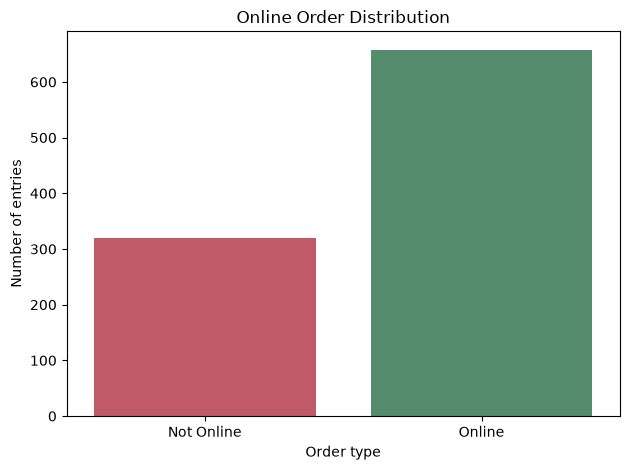

In [14]:

online_status = cleaned_df["online_order"].map({0: "Not Online", 1: "Online"})

sns.countplot(
    x=online_status,
    hue=online_status,
    order=["Not Online", "Online"],
    hue_order=["Not Online", "Online"],
    palette={"Not Online": "#D1495B", "Online": "#4C956C"},
    legend=False,
)
plt.title("Online Order Distribution")
plt.xlabel("Order type")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

Prompt: Create a visualization of the distribution of ratio to median purchase price.
<br>Ai: GPT-6 Luna

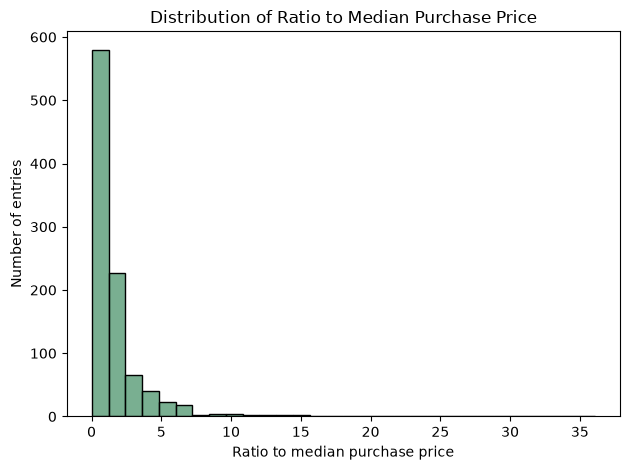

In [17]:

sns.histplot(
    data=cleaned_df,
    x="ratio_to_median_purchase_price",
    bins=30,
    color="#4C956C",
)
plt.title("Distribution of Ratio to Median Purchase Price")
plt.xlabel("Ratio to median purchase price")
plt.ylabel("Number of entries")
plt.tight_layout()
plt.show()

Prompt: Create a visualization that compares transactions with and without PIN and fraud.
Ai: GPT-6 Luna

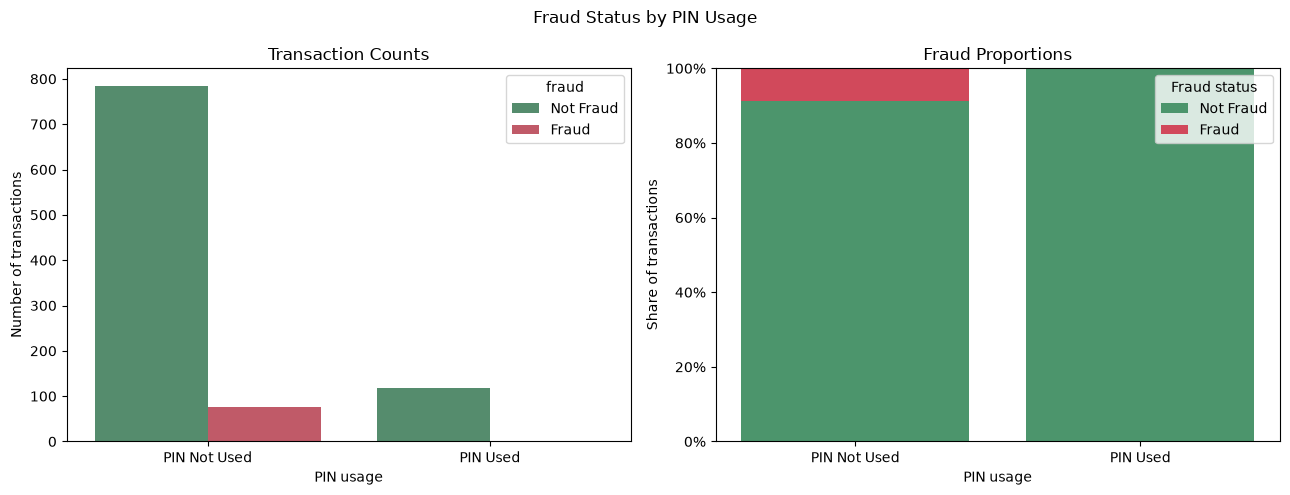

In [19]:
import numpy as np
from matplotlib.ticker import PercentFormatter

pin_status = cleaned_df["used_pin_number"].map({0: "PIN Not Used", 1: "PIN Used"})
fraud_status = cleaned_df["fraud"].map({0: "Not Fraud", 1: "Fraud"})
pin_order = ["PIN Not Used", "PIN Used"]
fraud_order = ["Not Fraud", "Fraud"]
fraud_palette = {"Not Fraud": "#4C956C", "Fraud": "#D1495B"}

pin_fraud_counts = pd.crosstab(pin_status, fraud_status).reindex(
    index=pin_order,
    columns=fraud_order,
    fill_value=0,
)
pin_fraud_proportions = pin_fraud_counts.div(pin_fraud_counts.sum(axis=1), axis=0)

fig, (ax_counts, ax_proportions) = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    x=pin_status,
    hue=fraud_status,
    order=pin_order,
    hue_order=fraud_order,
    palette=fraud_palette,
    ax=ax_counts,
)
ax_counts.set_title("Transaction Counts")
ax_counts.set_xlabel("PIN usage")
ax_counts.set_ylabel("Number of transactions")

bottom = np.zeros(len(pin_fraud_proportions))
for status in fraud_order:
    values = pin_fraud_proportions[status].to_numpy()
    ax_proportions.bar(
        pin_fraud_proportions.index,
        values,
        bottom=bottom,
        color=fraud_palette[status],
        label=status,
    )
    bottom += values

ax_proportions.yaxis.set_major_formatter(PercentFormatter(1))
ax_proportions.set_title("Fraud Proportions")
ax_proportions.set_xlabel("PIN usage")
ax_proportions.set_ylabel("Share of transactions")
ax_proportions.legend(title="Fraud status")

fig.suptitle("Fraud Status by PIN Usage")
fig.tight_layout()
plt.show()

Prompt: Can you do the same things a before but with chip use and fraud.
Ai: GPT-6 Luna

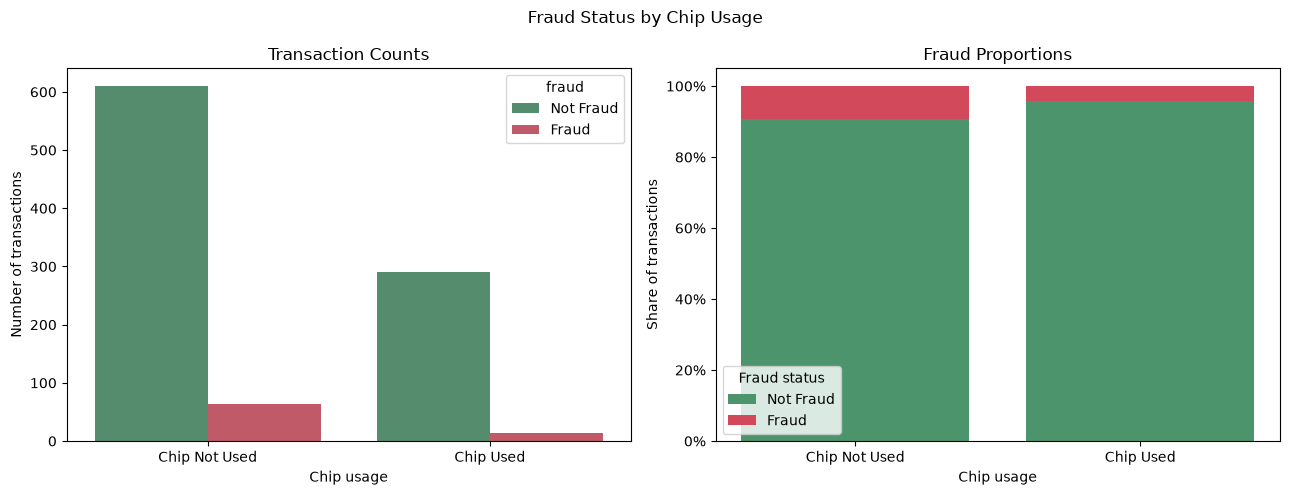

In [20]:

chip_status = cleaned_df["used_chip"].map({0: "Chip Not Used", 1: "Chip Used"})
fraud_status = cleaned_df["fraud"].map({0: "Not Fraud", 1: "Fraud"})
chip_order = ["Chip Not Used", "Chip Used"]
fraud_order = ["Not Fraud", "Fraud"]
fraud_palette = {"Not Fraud": "#4C956C", "Fraud": "#D1495B"}

chip_fraud_counts = pd.crosstab(chip_status, fraud_status).reindex(
    index=chip_order,
    columns=fraud_order,
    fill_value=0,
)
chip_fraud_proportions = chip_fraud_counts.div(chip_fraud_counts.sum(axis=1), axis=0)

fig, (ax_counts, ax_proportions) = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    x=chip_status,
    hue=fraud_status,
    order=chip_order,
    hue_order=fraud_order,
    palette=fraud_palette,
    ax=ax_counts,
)
ax_counts.set_title("Transaction Counts")
ax_counts.set_xlabel("Chip usage")
ax_counts.set_ylabel("Number of transactions")

bottom = np.zeros(len(chip_fraud_proportions))
for status in fraud_order:
    values = chip_fraud_proportions[status].to_numpy()
    ax_proportions.bar(
        chip_fraud_proportions.index,
        values,
        bottom=bottom,
        color=fraud_palette[status],
        label=status,
    )
    bottom += values

ax_proportions.yaxis.set_major_formatter(PercentFormatter(1))
ax_proportions.set_title("Fraud Proportions")
ax_proportions.set_xlabel("Chip usage")
ax_proportions.set_ylabel("Share of transactions")
ax_proportions.legend(title="Fraud status")

fig.suptitle("Fraud Status by Chip Usage")
fig.tight_layout()
plt.show()

Prompt: Do the same as before but with Online orders and fraud.
Ai: GPT-6 Luna

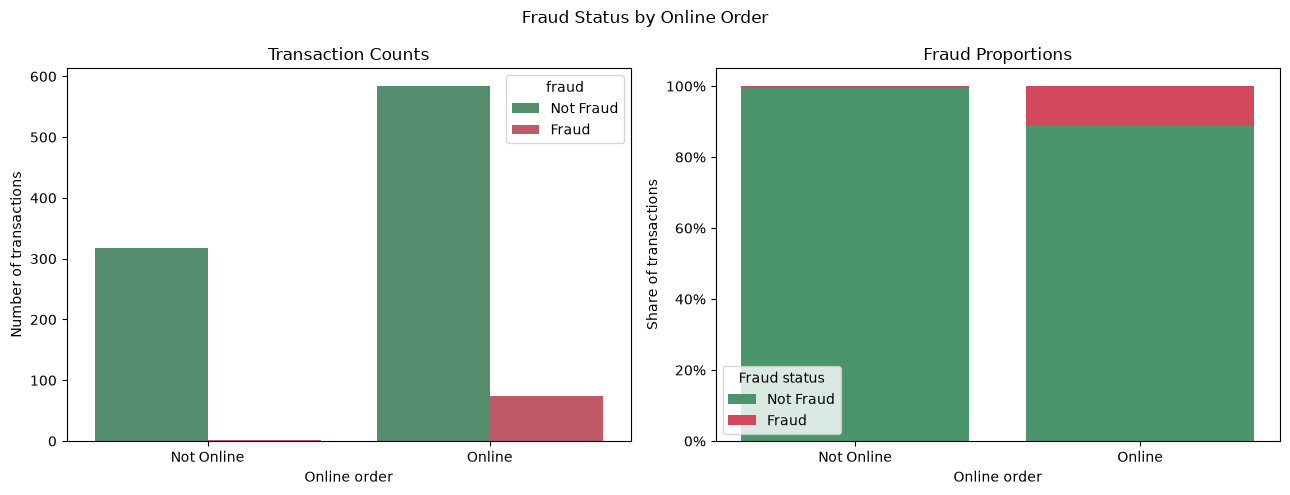

In [21]:

online_order_status = cleaned_df["online_order"].map({0: "Not Online", 1: "Online"})
fraud_status = cleaned_df["fraud"].map({0: "Not Fraud", 1: "Fraud"})
online_order_order = ["Not Online", "Online"]
fraud_order = ["Not Fraud", "Fraud"]
fraud_palette = {"Not Fraud": "#4C956C", "Fraud": "#D1495B"}

online_fraud_counts = pd.crosstab(online_order_status, fraud_status).reindex(
    index=online_order_order,
    columns=fraud_order,
    fill_value=0,
)
online_fraud_proportions = online_fraud_counts.div(online_fraud_counts.sum(axis=1), axis=0)

fig, (ax_counts, ax_proportions) = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    x=online_order_status,
    hue=fraud_status,
    order=online_order_order,
    hue_order=fraud_order,
    palette=fraud_palette,
    ax=ax_counts,
)
ax_counts.set_title("Transaction Counts")
ax_counts.set_xlabel("Online order")
ax_counts.set_ylabel("Number of transactions")

bottom = np.zeros(len(online_fraud_proportions))
for status in fraud_order:
    values = online_fraud_proportions[status].to_numpy()
    ax_proportions.bar(
        online_fraud_proportions.index,
        values,
        bottom=bottom,
        color=fraud_palette[status],
        label=status,
    )
    bottom += values

ax_proportions.yaxis.set_major_formatter(PercentFormatter(1))
ax_proportions.set_title("Fraud Proportions")
ax_proportions.set_xlabel("Online order")
ax_proportions.set_ylabel("Share of transactions")
ax_proportions.legend(title="Fraud status")

fig.suptitle("Fraud Status by Online Order")
fig.tight_layout()
plt.show()

Prompt: Create a visualization comparing fraud, distance from home and ratio to median purchase price.
Ai: GPT-6 Luna

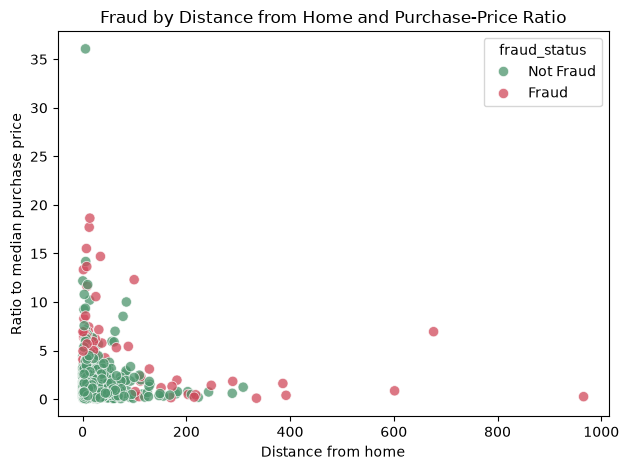

In [22]:

plot_data = cleaned_df.assign(
    fraud_status=cleaned_df["fraud"].map({0: "Not Fraud", 1: "Fraud"})
)

sns.scatterplot(
    data=plot_data,
    x="distance_from_home",
    y="ratio_to_median_purchase_price",
    hue="fraud_status",
    hue_order=["Not Fraud", "Fraud"],
    palette={"Not Fraud": "#4C956C", "Fraud": "#D1495B"},
    alpha=0.75,
    s=55,
)
plt.title("Fraud by Distance from Home and Purchase-Price Ratio")
plt.xlabel("Distance from home")
plt.ylabel("Ratio to median purchase price")
plt.tight_layout()
plt.show()